In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub

# Download latest version
path = kagglehub.dataset_download("uom190346a/sleep-health-and-lifestyle-dataset")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/uom190346a/sleep-health-and-lifestyle-dataset


# Data Loading and Cleaning
Load and clean the data:
* Replace 'nan' in Sleep disorder with "None"
* Split Blood Pressure in Systolic and Diastolic
* Remove olad Blood Pressure column

In [31]:
df = pd.read_csv("/kaggle/input/datasets/uom190346a/sleep-health-and-lifestyle-dataset/Sleep_health_and_lifestyle_dataset.csv", index_col="Person ID")
df["Sleep Disorder"] = df["Sleep Disorder"].fillna("None")
df['Systolic Blood Pressure'] = df['Blood Pressure'].apply(lambda x: int(x.split('/')[0]))
df['Diastolic Blood Pressure']= df['Blood Pressure'].apply(lambda x: int(x.split('/')[1]))
del df['Blood Pressure']

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 374 entries, 1 to 374
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Gender                   374 non-null    object 
 1   Age                      374 non-null    int64  
 2   Occupation               374 non-null    object 
 3   Sleep Duration           374 non-null    float64
 4   Quality of Sleep         374 non-null    int64  
 5   Physical Activity Level  374 non-null    int64  
 6   Stress Level             374 non-null    int64  
 7   BMI Category             374 non-null    object 
 8   Blood Pressure           374 non-null    object 
 9   Heart Rate               374 non-null    int64  
 10  Daily Steps              374 non-null    int64  
 11  Sleep Disorder           374 non-null    object 
dtypes: float64(1), int64(6), object(5)
memory usage: 38.0+ KB


In [32]:
df

,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Sleep Disorder,Systolic Blood Pressure,Diastolic Blood Pressure
Person ID,,,,,,,,,,,,,
1,Male,27,Software Engineer,6.1,6,42,6,Overweight,77,4200,None,126,83
2,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,None,125,80
3,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,None,125,80
4,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90
5,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90
...,...,...,...,...,...,...,...,...,...,...,...,...,...
370,Female,59,Nurse,8.1,9,75,3,Overweight,68,7000,Sleep Apnea,140,95
371,Female,59,Nurse,8.0,9,75,3,Overweight,68,7000,Sleep Apnea,140,95
372,Female,59,Nurse,8.1,9,75,3,Overweight,68,7000,Sleep Apnea,140,95


In [46]:
df.columns

Index(['Gender', 'Age', 'Occupation', 'Sleep Duration', 'Quality of Sleep',
       'Physical Activity Level', 'Stress Level', 'BMI Category', 'Heart Rate',
       'Daily Steps', 'Sleep Disorder', 'Systolic Blood Pressure',
       'Diastolic Blood Pressure'],
      dtype='object')

# Exploratory Analysis

## Discrete Variables

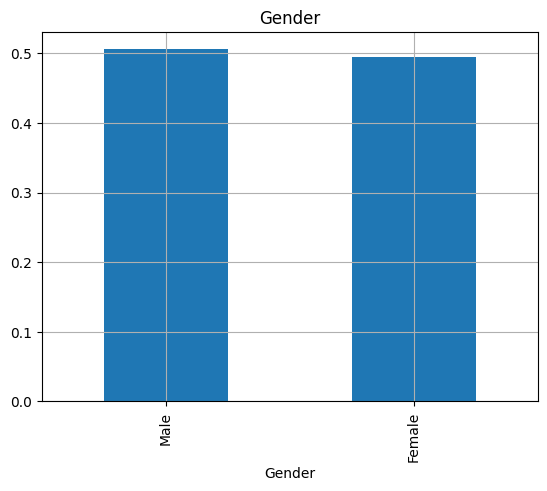

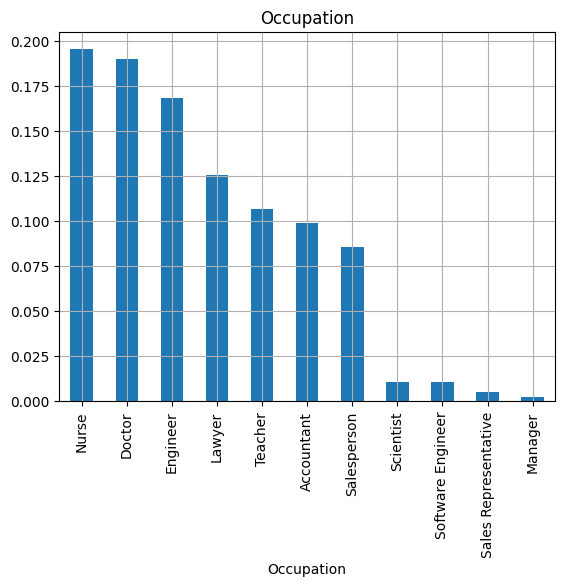

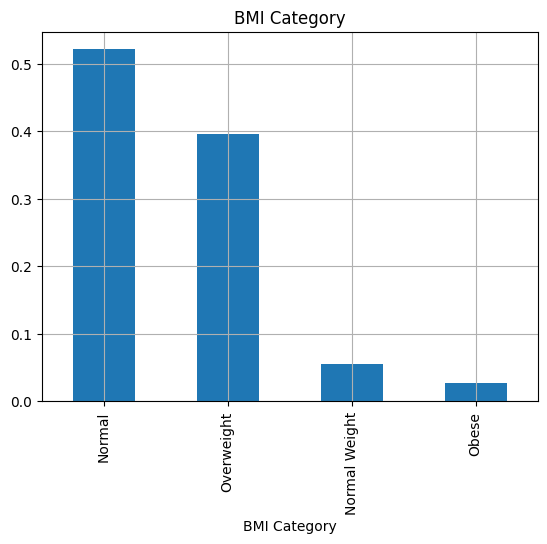

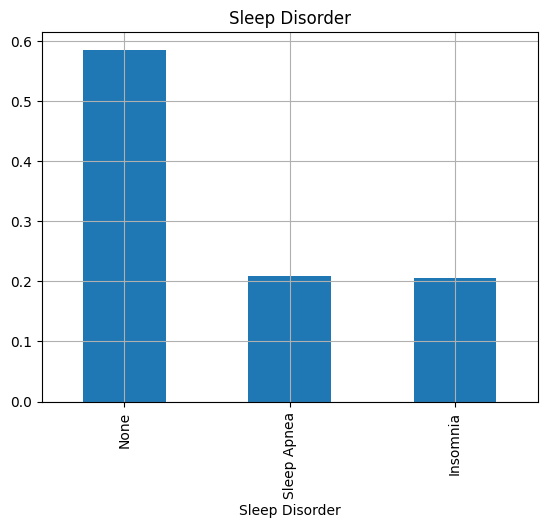

In [50]:
from matplotlib import pyplot as plt
for colname in ['Gender', 'Occupation', 'BMI Category', 'Sleep Disorder']:
    df[colname].value_counts(normalize=True).plot(kind='bar', title=colname)
    plt.grid()
    plt.show()

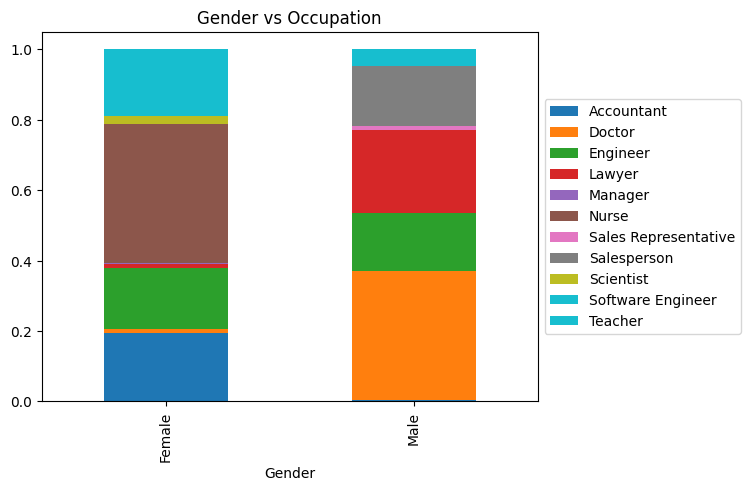

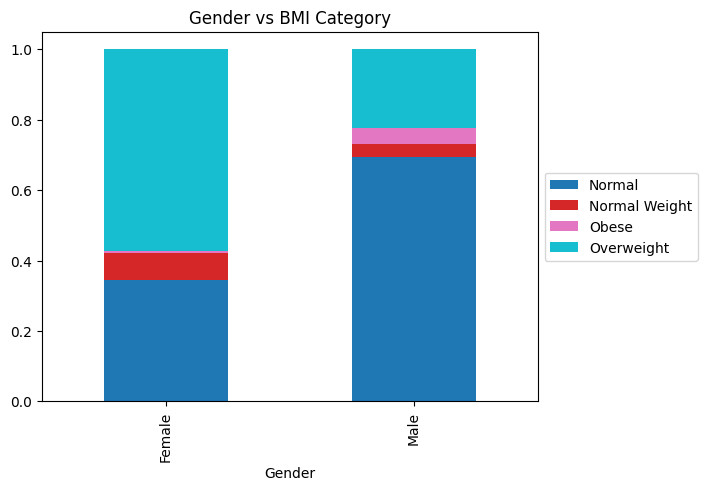

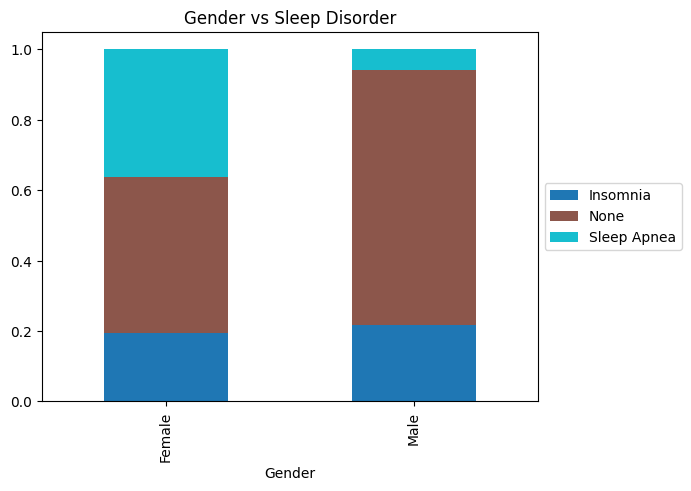

In [89]:
for colname in ['Occupation', 'BMI Category', 'Sleep Disorder']:
    pd.crosstab(df['Gender'], df[colname], normalize=0).plot.bar(stacked=True, cmap='tab10', title=f"Gender vs {colname}").legend(loc='center left',bbox_to_anchor=(1.0, 0.5));
    plt.show()

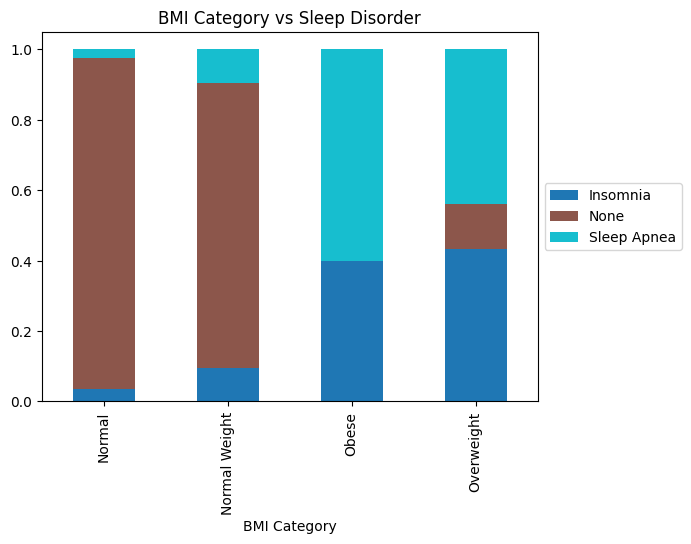

In [88]:
    pd.crosstab(df['BMI Category'], df['Sleep Disorder'], normalize=0).plot.bar(stacked=True, cmap='tab10', title=f"BMI Category vs Sleep Disorder").legend(loc='center left',bbox_to_anchor=(1.0, 0.5));


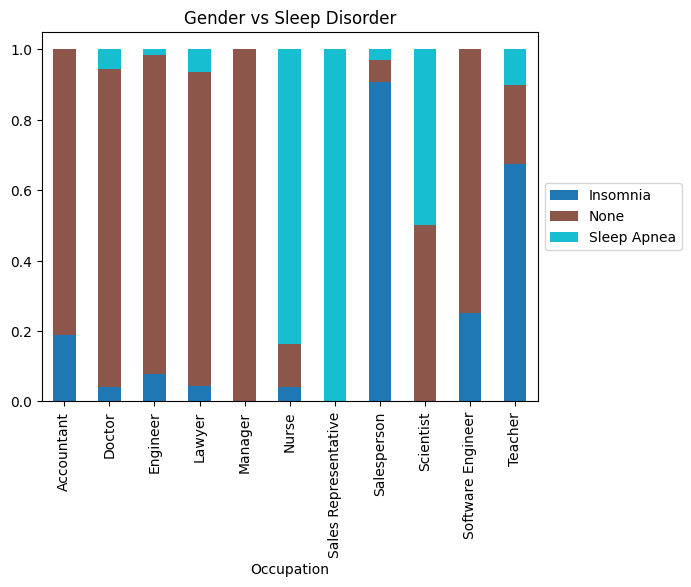

In [87]:
    pd.crosstab(df['Occupation'], df['Sleep Disorder'], normalize=0).plot.bar(stacked=True, cmap='tab10', title=f"Gender vs {colname}").legend(loc='center left',bbox_to_anchor=(1.0, 0.5));


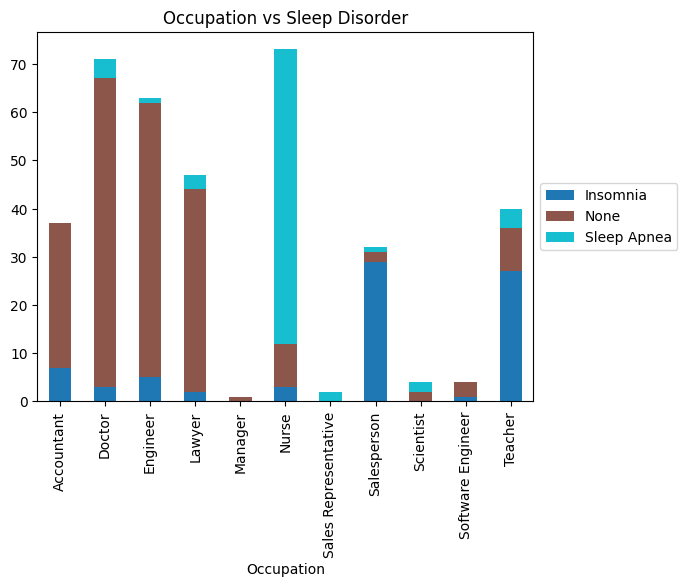

In [86]:
    pd.crosstab(df['Occupation'], df['Sleep Disorder']).plot.bar(stacked=True, cmap='tab10', title=f"Occupation vs Sleep Disorder").legend(loc='center left',bbox_to_anchor=(1.0, 0.5));


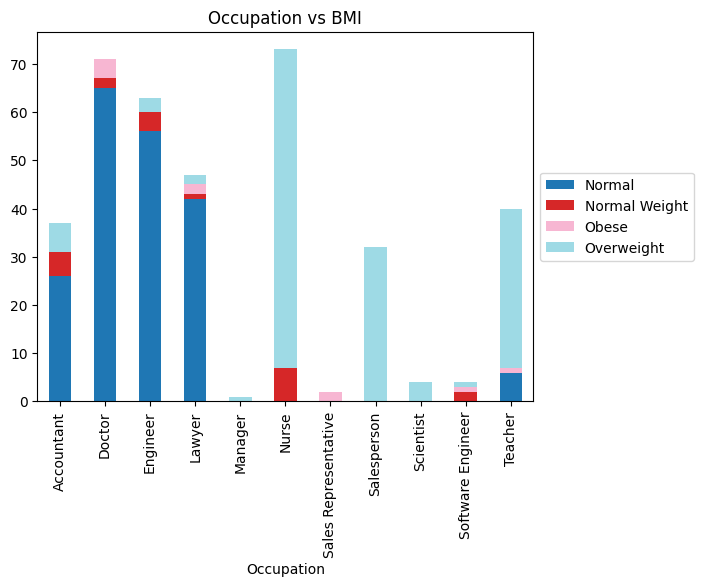

In [84]:
pd.crosstab(df['Occupation'], df['BMI Category']).plot.bar(stacked=True, cmap='tab20', title=f"Occupation vs BMI").legend(loc='center left',bbox_to_anchor=(1.0, 0.5));


Comments:
- Occupations looks correlated with BMI ...

## Continuous Variables

Temp dataframe with just continuous variables

In [96]:
df_continuous = df.drop(['Gender', 'Occupation', 'BMI Category', 'Sleep Disorder'], axis=1)
df_continuous

,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps,Systolic Blood Pressure,Diastolic Blood Pressure
Person ID,,,,,,,,,
1,27,6.1,6,42,6,77,4200,126,83
2,28,6.2,6,60,8,75,10000,125,80
3,28,6.2,6,60,8,75,10000,125,80
4,28,5.9,4,30,8,85,3000,140,90
5,28,5.9,4,30,8,85,3000,140,90
...,...,...,...,...,...,...,...,...,...
370,59,8.1,9,75,3,68,7000,140,95
371,59,8.0,9,75,3,68,7000,140,95
372,59,8.1,9,75,3,68,7000,140,95


<Axes: >

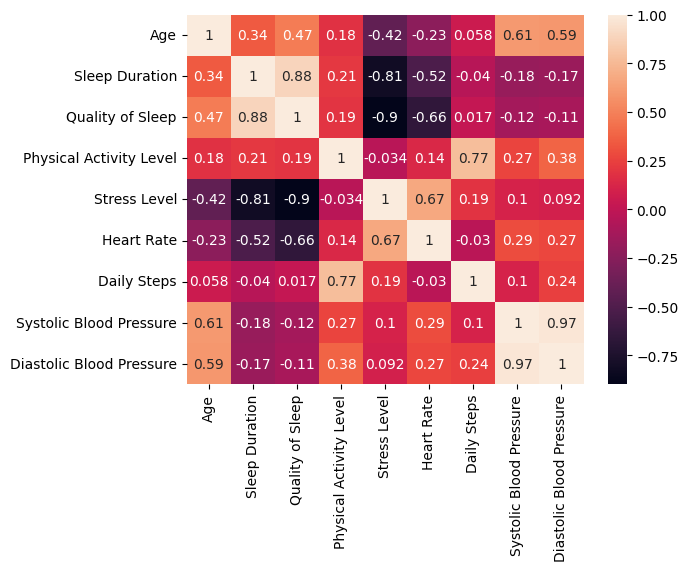

In [98]:
import seaborn as sns
sns.heatmap(df_continuous.corr(), annot=True)

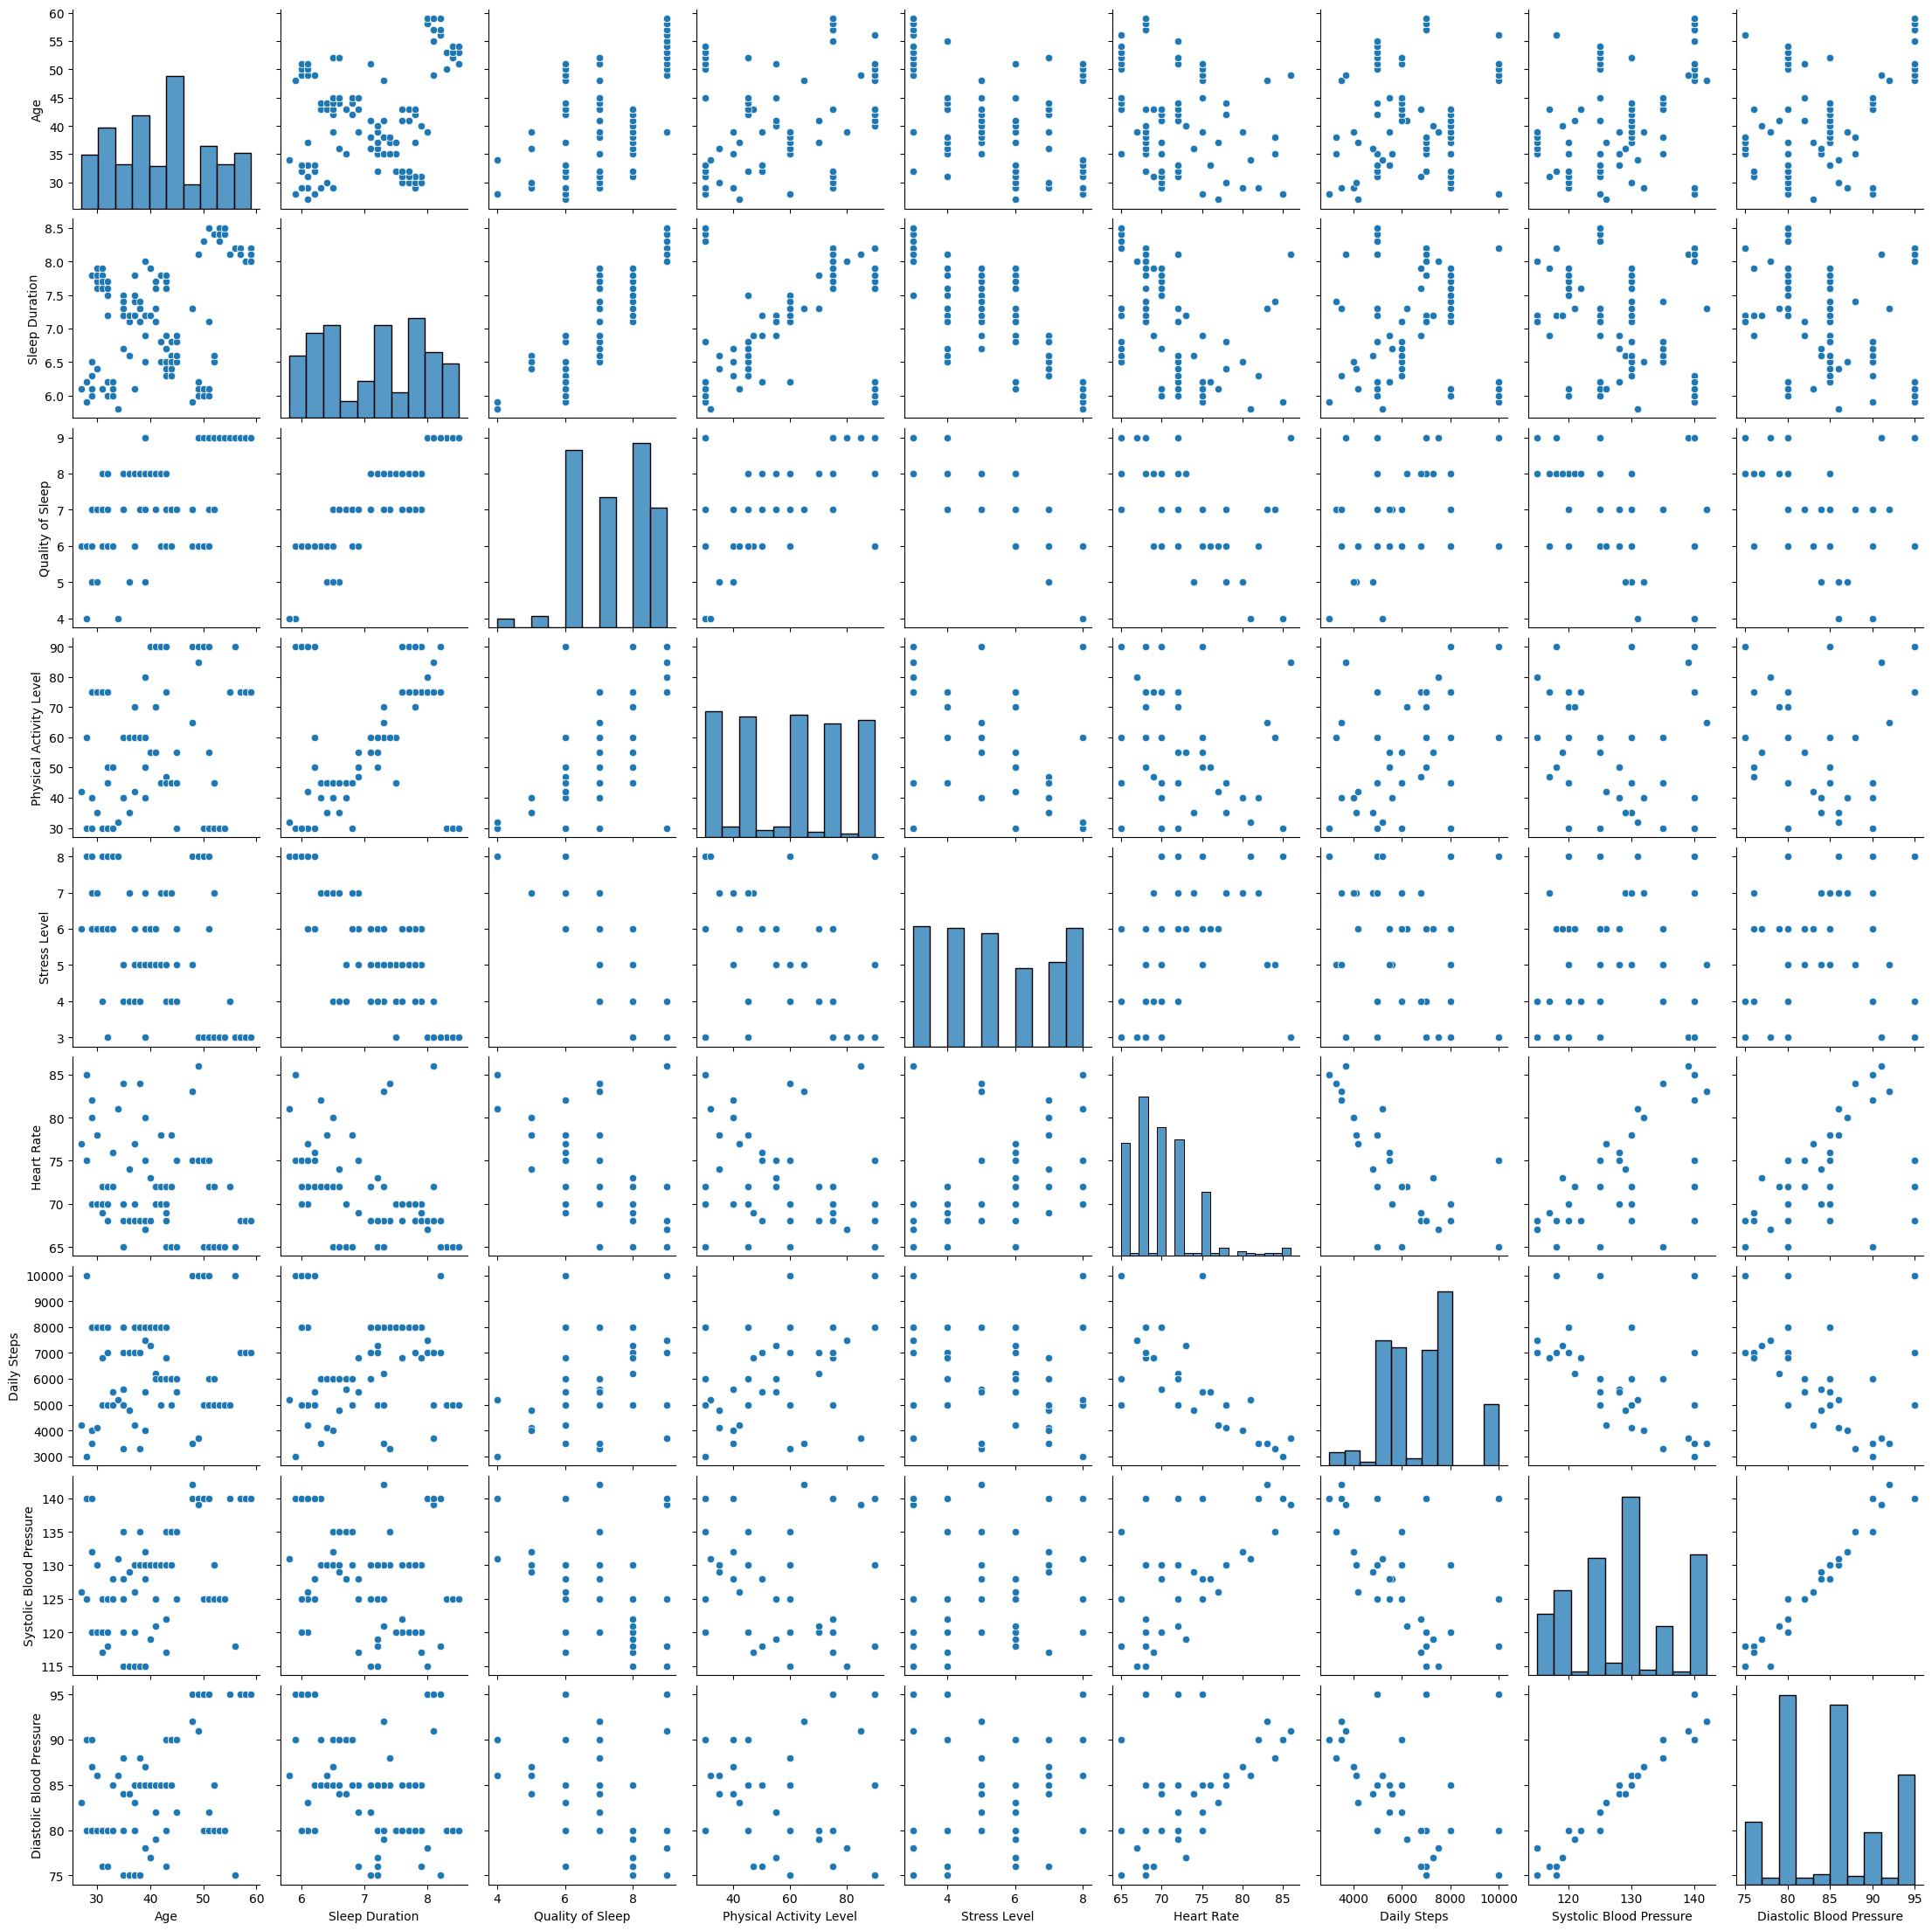

In [99]:
sns.pairplot(df_continuous)

# Domande di analisi
* Esiste una relazione tra l'occupazione e i livelli di stress?
* Esiste un legame tra essere in sovrappeso e soffrire di apnee notturne?
* Il livello di attività fisica cambia con l'età?

## Esiste una relazione tra l'occupazione e i livelli di stress?


In [103]:
df['Stress Level'].unique()

array([6, 8, 7, 4, 3, 5])

<Axes: xlabel='Occupation'>

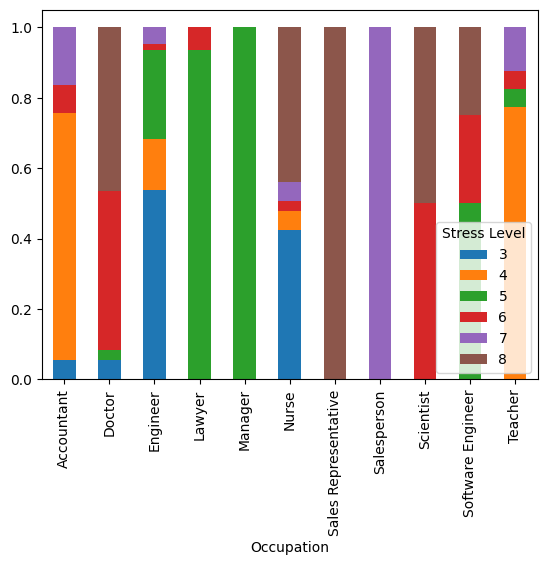

In [111]:
crosstab_occupation_stress_level = pd.crosstab(df['Occupation'], df['Stress Level'])

pd.crosstab(df['Occupation'], df['Stress Level'], normalize=0).plot.bar(stacked=True)

In [112]:
crosstab_occupation_stress_level

Stress Level,3,4,5,6,7,8
Occupation,,,,,,
Accountant,2,26,0,3,6,0
Doctor,4,0,2,32,0,33
Engineer,34,9,16,1,3,0
Lawyer,0,0,44,3,0,0
Manager,0,0,1,0,0,0
Nurse,31,4,0,2,4,32
Sales Representative,0,0,0,0,0,2
Salesperson,0,0,0,0,32,0
Scientist,0,0,0,2,0,2


In [113]:
from scipy.stats import chi2_contingency
chi2_contingency(crosstab_occupation_stress_level)

Chi2ContingencyResult(statistic=np.float64(853.0570553050686), pvalue=np.float64(1.294642417616891e-146), dof=50, expected_freq=array([[ 7.02406417,  6.92513369,  6.62834225,  4.55080214,  4.94652406,
         6.92513369],
       [13.47860963, 13.28877005, 12.71925134,  8.73262032,  9.49197861,
        13.28877005],
       [11.95989305, 11.79144385, 11.28609626,  7.7486631 ,  8.42245989,
        11.79144385],
       [ 8.92245989,  8.79679144,  8.4197861 ,  5.78074866,  6.28342246,
         8.79679144],
       [ 0.18983957,  0.18716578,  0.17914439,  0.12299465,  0.13368984,
         0.18716578],
       [13.85828877, 13.6631016 , 13.07754011,  8.97860963,  9.75935829,
        13.6631016 ],
       [ 0.37967914,  0.37433155,  0.35828877,  0.2459893 ,  0.26737968,
         0.37433155],
       [ 6.07486631,  5.98930481,  5.73262032,  3.93582888,  4.27807487,
         5.98930481],
       [ 0.75935829,  0.7486631 ,  0.71657754,  0.49197861,  0.53475936,
         0.7486631 ],
       [ 0.759358

In [114]:
from scipy.stats.contingency import association
print(f"{association(crosstab_occupation_stress_level):0.2f}")

0.68


In [122]:
df['Stress Level2'] = df['Stress Level'].map({3:1, 4:1, 5:1, 6:2, 7:2, 8:2})

In [140]:
o = df['Occupation'].copy()
o[o=='Engineer'] = 'Technical Person'
o[o=='Scientist'] = 'Technical Person'
o[o=='Software Engineer'] = 'Technical Person'
df['Occupation2'] = o
df2 = df.copy()
df2 = df2[df2['Occupation2'] != 'Manager']
df2 = df2[df2['Occupation2'] != 'Sales Representative']
df2 = df2[df2['Occupation2'] != 'Salesperson']
df2 = df2[df2['Occupation2'] != 'Lawyer']

In [142]:
crosstab2 = pd.crosstab(df2['Occupation2'], df2['Stress Level2'])

In [143]:
chi2_contingency(crosstab2)

Chi2ContingencyResult(statistic=np.float64(109.97412938490145), pvalue=np.float64(7.370703254111213e-23), dof=4, expected_freq=array([[20.65410959, 16.34589041],
       [39.63356164, 31.36643836],
       [40.75      , 32.25      ],
       [22.32876712, 17.67123288],
       [39.63356164, 31.36643836]]))

In [144]:
association(crosstab2)

0.6136967742869522

<Axes: xlabel='Occupation2'>

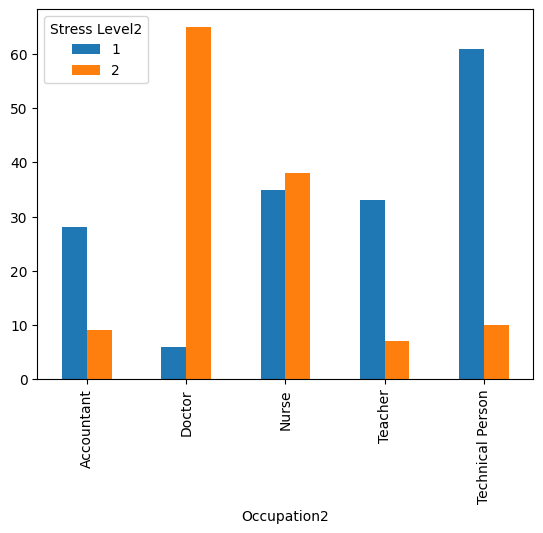

In [145]:
crosstab2.plot.bar()

# One Sample t-test

In [146]:
df

,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Sleep Disorder,Systolic Blood Pressure,Diastolic Blood Pressure,Stress Level2,Occupation2
Person ID,,,,,,,,,,,,,,,
1,Male,27,Software Engineer,6.1,6,42,6,Overweight,77,4200,None,126,83,2,Technical Person
2,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,None,125,80,2,Doctor
3,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,None,125,80,2,Doctor
4,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90,2,Sales Representative
5,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90,2,Sales Representative
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
370,Female,59,Nurse,8.1,9,75,3,Overweight,68,7000,Sleep Apnea,140,95,1,Nurse
371,Female,59,Nurse,8.0,9,75,3,Overweight,68,7000,Sleep Apnea,140,95,1,Nurse
372,Female,59,Nurse,8.1,9,75,3,Overweight,68,7000,Sleep Apnea,140,95,1,Nurse


In [149]:
df['Age'].describe()

count    374.000000
mean      42.184492
std        8.673133
min       27.000000
25%       35.250000
50%       43.000000
75%       50.000000
max       59.000000
Name: Age, dtype: float64

In [153]:
import numpy as np
from scipy import stats

# Define the null hypothesis mean (population mean you want to test against)
null_hypothesis_mean = 42

# Perform a one-sample t-test
t_stat, p_value = stats.ttest_1samp(df['Age'], null_hypothesis_mean)

In [161]:
df.groupby('Gender')[['Age','Sleep Duration','Quality of Sleep', 'Physical Activity Level', 'Stress Level', 'Heart Rate']].mean()

,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate
Gender,,,,,,
Female,47.405405,7.229730,7.664865,59.140541,4.675676,69.259459
Male,37.074074,7.036508,6.968254,59.201058,6.079365,71.052910


In [164]:
import scipy.stats as stats

h1 = df[df['Gender']=='Male']['Sleep Duration']
h2 = df[df['Gender']=='Female']['Sleep Duration']

# Perform independent two-sample t-test
t_stat, p_value = stats.ttest_ind(h1, h2)

In [165]:
t_stat

np.float64(-2.3624469898393397)

In [166]:
p_value

np.float64(0.018668859270607456)

In [169]:
df['Gender'].value_counts().values

array([189, 185])

In [170]:
len(df)/2

187.0

In [183]:
len(df)/2/10

18.7

In [192]:
import seaborn as sns
import pandas as pd
from scipy.stats import chisquare

observed_frequencies = [189,195] #189, 195

# Define expected frequencies that closely match the observed data
expected_frequencies = [len(df)/2, len(df)/2]

chi2, p_value = chisquare(f_obs=observed_frequencies, f_exp=expected_frequencies)
p_value

ValueError: For each axis slice, the sum of the observed frequencies must agree with the sum of the expected frequencies to a relative tolerance of 1.4901161193847656e-08, but the percent differences are:
0.026737967914438502

np.float64(0.836138661741041)

<Axes: >

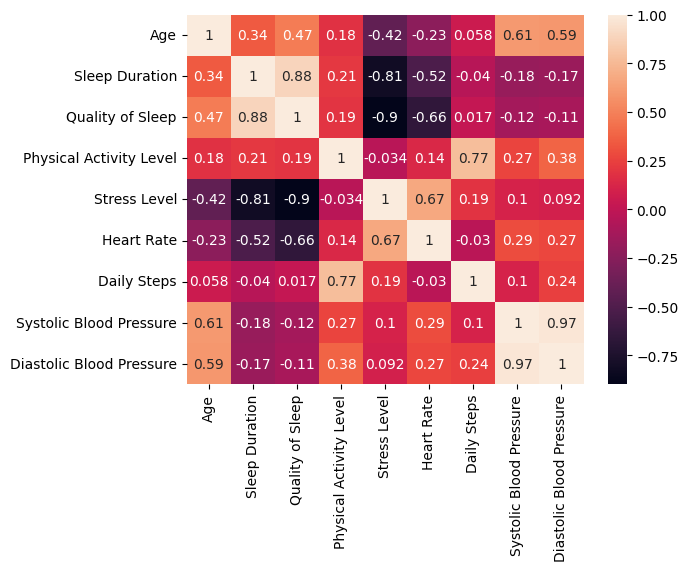

In [193]:
import seaborn as sns
sns.heatmap(df_continuous.corr(), annot=True)

In [197]:
from scipy.stats import pearsonr
pearsonr(df['Daily Steps'],df['Quality of Sleep'])

PearsonRResult(statistic=np.float64(0.01679141492471675), pvalue=np.float64(0.7461906652961119))

In [198]:
from scipy.stats import pearsonr
pearsonr(df['Systolic Blood Pressure'],df['Quality of Sleep'])

PearsonRResult(statistic=np.float64(-0.12163199613350834), pvalue=np.float64(0.01861662688136553))

In [199]:
from scipy.stats import pearsonr
pearsonr(df['Stress Level'],df['Quality of Sleep'])

PearsonRResult(statistic=np.float64(-0.8987520310040416), pvalue=np.float64(2.8801242409433364e-135))

In [207]:
pearsonr([1,2,3 ,4],[1,2,3.4,4 ])

PearsonRResult(statistic=np.float64(0.9898030839149452), pvalue=np.float64(0.010196916085054797))